<a href="https://colab.research.google.com/github/Houdaimarine/Tifinagh-LeNet5/blob/main/Tifinagh_LeNet5_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install -q kagglehub


import kagglehub
path = kagglehub.dataset_download("benaddym/amazigh-handwritten-character-database-amhcd")

print("dataset telecharger", path)

Using Colab cache for faster access to the 'amazigh-handwritten-character-database-amhcd' dataset.
dataset telecharger /kaggle/input/amazigh-handwritten-character-database-amhcd


Téléchargement du dataset depuis Kaggle...
Using Colab cache for faster access to the 'amazigh-handwritten-character-database-amhcd' dataset.
Chemin d'origine du téléchargement : /kaggle/input/amazigh-handwritten-character-database-amhcd
Dossier cible retenu (Target Dir) : /kaggle/input/amazigh-handwritten-character-database-amhcd/AMHCD_64/AMHCD_64
Using device : cuda
Nombre de classes détectées avec succès : 33
Images d'entraînement : 20592 | Images de validation : 5148
Affichage d'un échantillon d'images du Dataset...


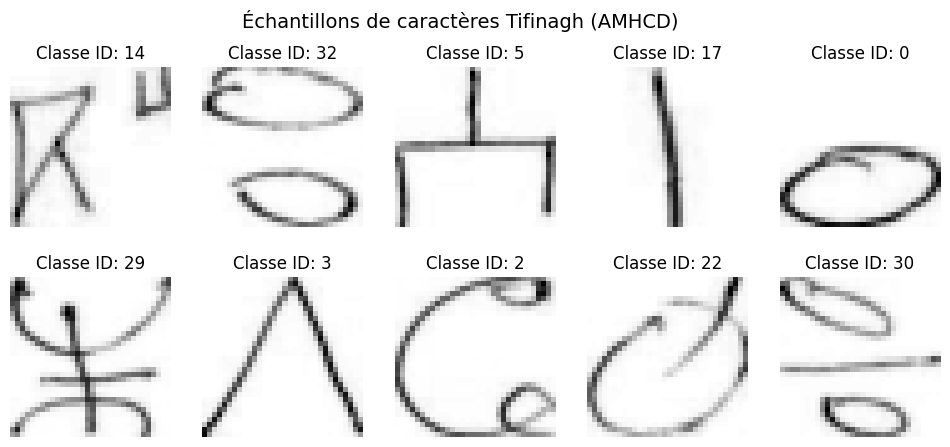

LeNet5_Tifinagh(
  (c1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (relu1): ReLU()
  (s2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (c3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (relu3): ReLU()
  (s4): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (c5): Linear(in_features=400, out_features=120, bias=True)
  (relu5): ReLU()
  (f6): Linear(in_features=120, out_features=84, bias=True)
  (relu6): ReLU()
  (output): Linear(in_features=84, out_features=33, bias=True)
)
Début de l'entraînement du modèle...
Epoch [1/5] | Train Loss: 1.8024 - Train Acc: 49.76% | Val Loss: 0.8659 - Val Acc: 76.11%
Epoch [2/5] | Train Loss: 0.6242 - Train Acc: 83.12% | Val Loss: 0.4859 - Val Acc: 87.32%
Epoch [3/5] | Train Loss: 0.3873 - Train Acc: 89.26% | Val Loss: 0.3347 - Val Acc: 90.56%
Epoch [4/5] | Train Loss: 0.2842 - Train Acc: 92.02% | Val Loss: 0.2864 - Val Acc: 91.71%
Epoch [5/5] | Train Loss: 0.2291 - Train Acc: 93.38% | Val Loss: 0.2273 - Val Acc: 93.40%
Affichage des rés

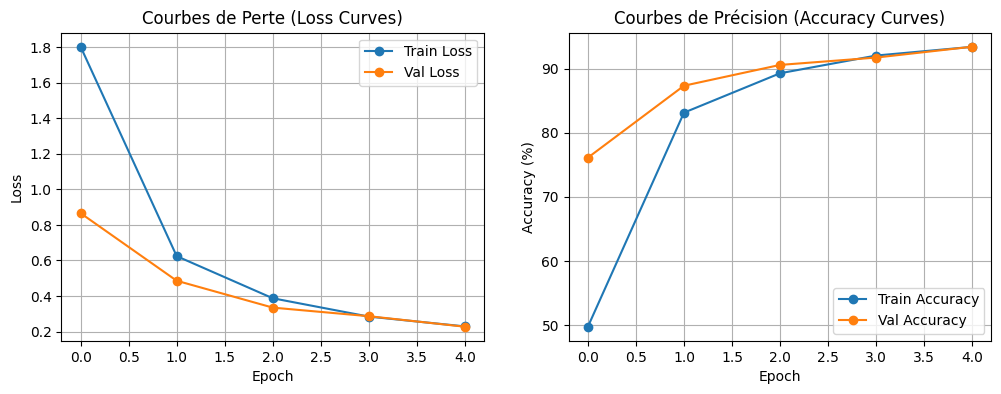

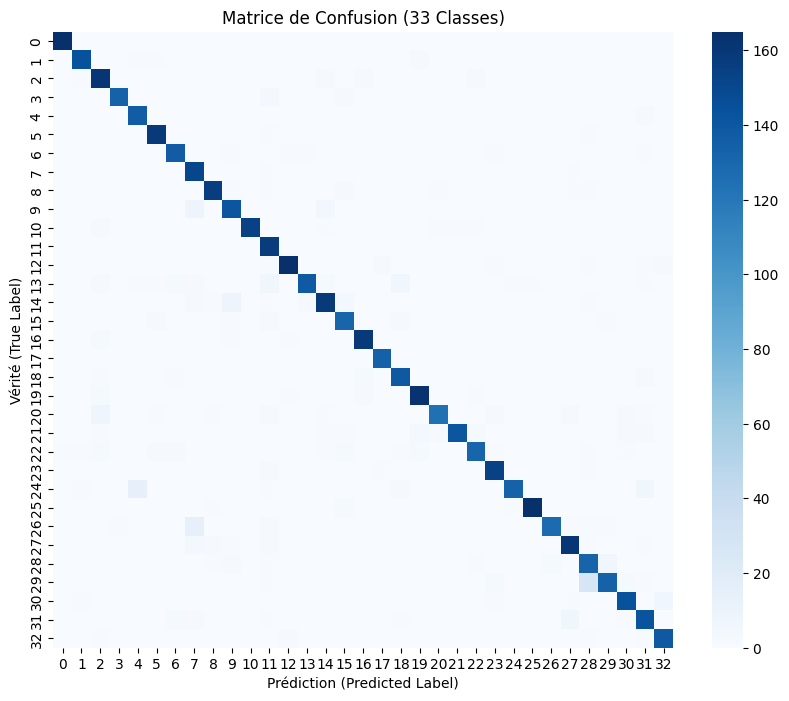

Affichage des Feature Maps (Interprétabilité du modèle)...


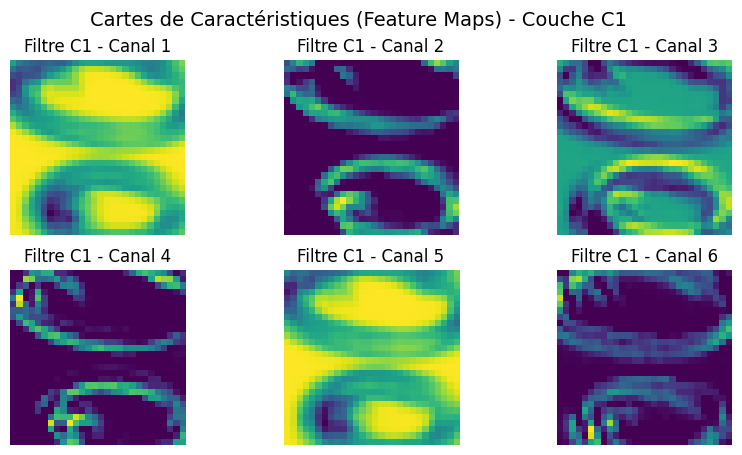

In [9]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import kagglehub


# 1. TÉLÉCHARGEMENT ET CORRECTION DU CHEMIN DU DATASET

print("Téléchargement du dataset depuis Kaggle...")
path = kagglehub.dataset_download("benaddym/amazigh-handwritten-character-database-amhcd")
print("Chemin d'origine du téléchargement :", path)

# Recherche automatique du dossier contenant les classes (les 33 caractères Tifinagh)
target_dir = None
for root, dirs, files in os.walk(path):
    if 'AMHCD_64' in root and len(dirs) >= 30:
        target_dir = root
        break
    if len(dirs) >= 30:
        target_dir = root

if not target_dir:
    for root, dirs, files in os.walk(path):
        if 'amhcd_64' in dirs:
            target_dir = os.path.join(root, 'amhcd_64')
            break

if not target_dir:
    target_dir = path

print(f"Dossier cible retenu (Target Dir) : {target_dir}")


# 2. CONFIGURATION DU DEVICE (GPU / CPU)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device : {device}")


# 3. PRÉTRAITEMENT ET DATALOADERS

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Chargement du dataset avec ImageFolder
dataset = ImageFolder(root=target_dir, transform=transform)
num_classes = len(dataset.classes)
print(f"Nombre de classes détectées avec succès : {num_classes}")

# Division du dataset en Train (80%) et Validation (20%)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
print(f"Images d'entraînement : {len(train_dataset)} | Images de validation : {len(val_dataset)}")


# NOUVEAU GRAPHE 1 : Aperçu d'échantillons du Dataset Tifinagh

def plot_sample_images(data_loader):
    dataiter = iter(data_loader)
    images, labels = next(dataiter)

    plt.figure(figsize=(12, 5))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        img = images[i].numpy().squeeze()
        img = (img * 0.5) + 0.5  # Inverser la normalisation
        plt.imshow(img, cmap='gray')
        plt.title(f"Classe ID: {labels[i].item()}")
        plt.axis('off')
    plt.suptitle("Échantillons de caractères Tifinagh (AMHCD)", fontsize=14)
    plt.show()

print("Affichage d'un échantillon d'images du Dataset...")
plot_sample_images(train_loader)


# 4. ARCHITECTURE DE LENET-5 MODIFIÉ (Dynamique selon le nombre de classes)

class LeNet5_Tifinagh(nn.Module):
    def __init__(self, num_classes=33):
        super(LeNet5_Tifinagh, self).__init__()
        # C1 : Couche de Convolution (1 canal d'entrée -> 6 filtres 5x5) -> 32x32 vers 28x28
        self.c1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1)
        self.relu1 = nn.ReLU()
        # S2 : Couche de Pooling Moyen (2x2, stride 2) -> 28x28 vers 14x14
        self.s2 = nn.AvgPool2d(kernel_size=2, stride=2)

        # C3 : Couche de Convolution (6 -> 16 filtres 5x5) -> 14x14 vers 10x10
        self.c3 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1)
        self.relu3 = nn.ReLU()
        # S4 : Couche de Pooling Moyen (2x2, stride 2) -> 10x10 vers 5x5
        self.s4 = nn.AvgPool2d(kernel_size=2, stride=2)

        # Aplatissement (Flatten size: 16 * 5 * 5 = 400)
        # C5 : Couche Fully Connected (120 neurones)
        self.c5 = nn.Linear(16 * 5 * 5, 120)
        self.relu5 = nn.ReLU()

        # F6 : Couche Fully Connected (84 neurones)
        self.f6 = nn.Linear(120, 84)
        self.relu6 = nn.ReLU()

        # Couche de Sortie (Output) : Nombre dynamique de classes (33)
        self.output = nn.Linear(84, num_classes)

    def forward(self, x):
        x = self.relu1(self.c1(x))
        x = self.s2(x)
        x = self.relu3(self.c3(x))
        x = self.s4(x)
        x = x.view(-1, 16 * 5 * 5) # Aplatissement des tensors
        x = self.relu5(self.c5(x))
        x = self.relu6(self.f6(x))
        x = self.output(x)
        return x

model = LeNet5_Tifinagh(num_classes=num_classes).to(device)
print(model)


# 5. FONCTIONS D'ENTRAÎNEMENT ET DE VALIDATION

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=5):
    train_losses, val_losses = [], []
    train_accuracies, val_accuracies = [], []

    for epoch in range(num_epochs):
        # Phase d'entraînement
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = 100 * correct_train / total_train
        train_losses.append(epoch_train_loss)
        train_accuracies.append(epoch_train_acc)

        # Phase de validation
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        epoch_val_loss = val_loss / len(val_loader.dataset)
        epoch_val_acc = 100 * correct_val / total_val
        val_losses.append(epoch_val_loss)
        val_accuracies.append(epoch_val_acc)

        print(f"Epoch [{epoch+1}/{num_epochs}] | "
              f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% | "
              f"Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.2f}%")

    return train_losses, val_losses, train_accuracies, val_accuracies


# 6. FONCTIONS DE VISUALISATION (Courbes, Matrice de Confusion & Feature Maps)

def plot_metrics(train_losses, val_losses, train_accuracies, val_accuracies):
    plt.figure(figsize=(12, 4))

    # Graphe de la Loss (Perte) avec marqueurs et grille
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss', marker='o')
    plt.plot(val_losses, label='Val Loss', marker='o')
    plt.title('Courbes de Perte (Loss Curves)')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # Graphe de l'Accuracy (Précision) avec marqueurs et grille
    plt.subplot(1, 2, 2)
    plt.plot(train_accuracies, label='Train Accuracy', marker='o')
    plt.plot(val_accuracies, label='Val Accuracy', marker='o')
    plt.title('Courbes de Précision (Accuracy Curves)')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.grid(True)

    plt.show()

def plot_confusion_matrix(model, data_loader, num_classes):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    # Génération de la matrice de confusion pour toutes les classes
    cm = confusion_matrix(all_labels, all_preds, labels=range(num_classes))
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=False, fmt='d', cmap='Blues')
    plt.title(f'Matrice de Confusion ({num_classes} Classes)')
    plt.xlabel('Prédiction (Predicted Label)')
    plt.ylabel('Vérité (True Label)')
    plt.show()


# NOUVEAU GRAPHE 2 : Visualisation des Feature Maps (Filtres de la couche C1)

def plot_feature_maps(model, data_loader):
    model.eval()
    images, _ = next(iter(data_loader))
    sample_image = images[0].unsqueeze(0).to(device)

    with torch.no_grad():
        feature_maps = model.relu1(model.c1(sample_image))

    feature_maps = feature_maps.squeeze(0).cpu()

    plt.figure(figsize=(10, 5))
    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(feature_maps[i].numpy(), cmap='viridis')
        plt.title(f'Filtre C1 - Canal {i+1}')
        plt.axis('off')
    plt.suptitle("Cartes de Caractéristiques (Feature Maps) - Couche C1", fontsize=14)
    plt.show()


# 7. LANCEMENT DE L'ENTRAÎNEMENT ET DES RÉSULTATS

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Début de l'entraînement du modèle...")
train_losses, val_losses, train_acc, val_acc = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=5)

print("Affichage des résultats et des graphiques...")
plot_metrics(train_losses, val_losses, train_acc, val_acc)
plot_confusion_matrix(model, val_loader, num_classes=num_classes)

print("Affichage des Feature Maps (Interprétabilité du modèle)...")
plot_feature_maps(model, val_loader)